Zeros: [-1. -1.]
Poles: [0.25+0.4330127j 0.25-0.4330127j]


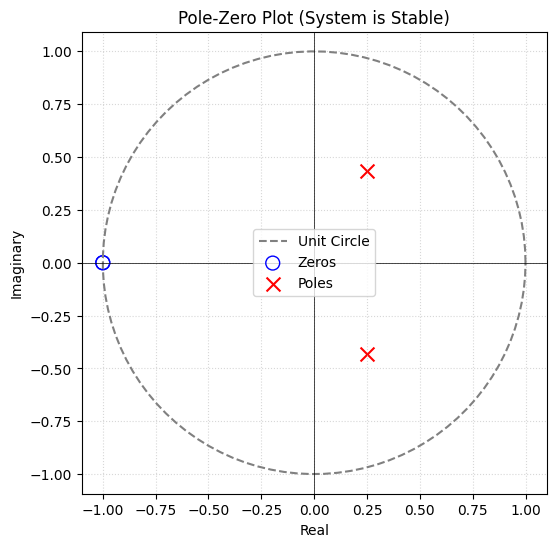

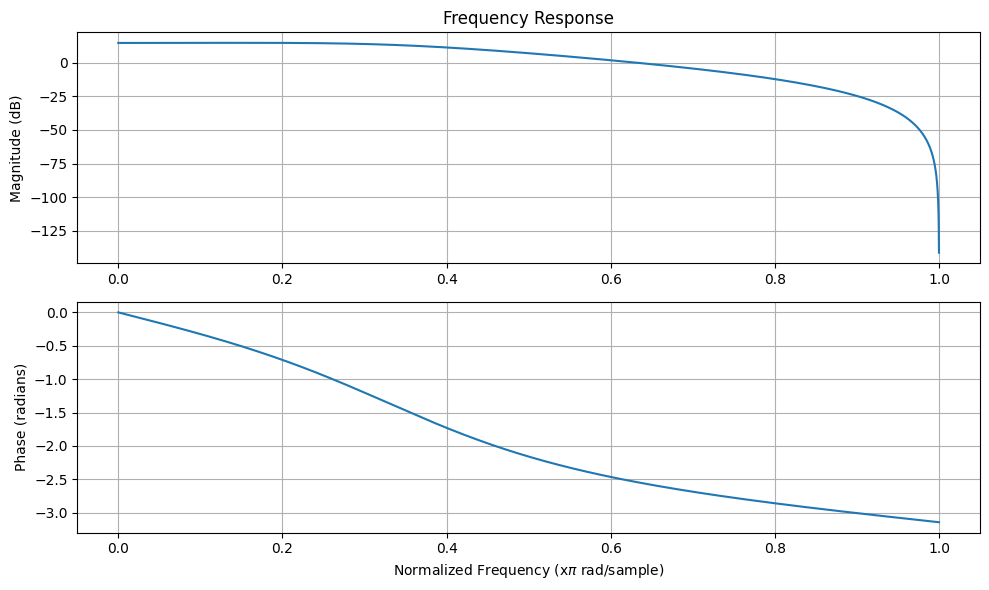

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define system coefficients: H(z) = B(z) / A(z)
# Example: H(z) = (1 + 2z^-1 + z^-2) / (1 - 0.5z^-1 + 0.25z^-2)
b = np.array([1.0, 2.0, 1.0])
a = np.array([1.0, -0.5, 0.25])

# Calculate zeros, poles, and system gain
zeros, poles, k = signal.tf2zpk(b, a)
print("Zeros:", zeros)
print("Poles:", poles)

# Plot Poles and Zeros on a Complex Z-Plane
fig, ax = plt.subplots(figsize=(6, 6))

# Draw unit circle
theta = np.linspace(0, 2 * np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--', label='Unit Circle')

# Plot zeros and poles
ax.scatter(np.real(zeros), np.imag(zeros), s=100, marker='o', facecolors='none', edgecolors='blue', label='Zeros')
ax.scatter(np.real(poles), np.imag(poles), s=100, marker='x', color='red', label='Poles')

# Annotate stability
is_stable = all(np.abs(poles) < 1)
plt.title(f"Pole-Zero Plot (System is {'Stable' if is_stable else 'Unstable'})")
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend()
plt.axis('equal')
plt.show()

# Frequency response calculation
w, h = signal.freqz(b, a, worN=8000)

# Plot magnitude and phase response
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(w / np.pi, 20 * np.log10(np.abs(h) + 1e-12))
plt.title('Frequency Response')
plt.ylabel('Magnitude (dB)')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(w / np.pi, np.angle(h))
plt.xlabel(r'Normalized Frequency (x$\pi$ rad/sample)')
plt.ylabel('Phase (radians)')
plt.grid(True)
plt.tight_layout()
plt.show()

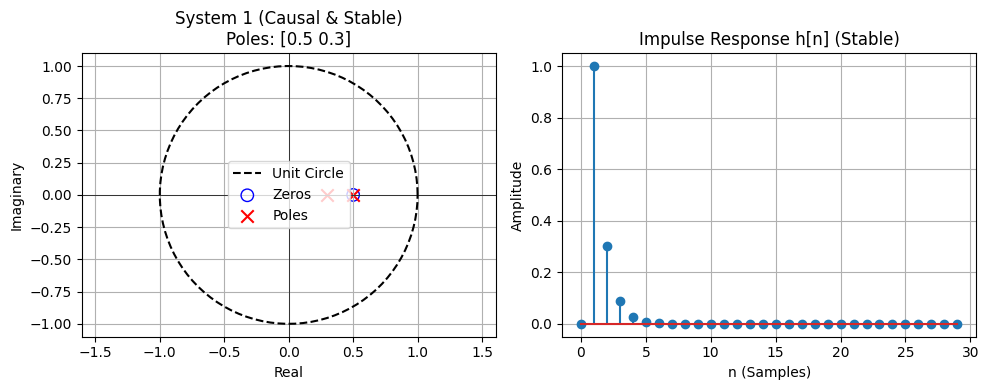

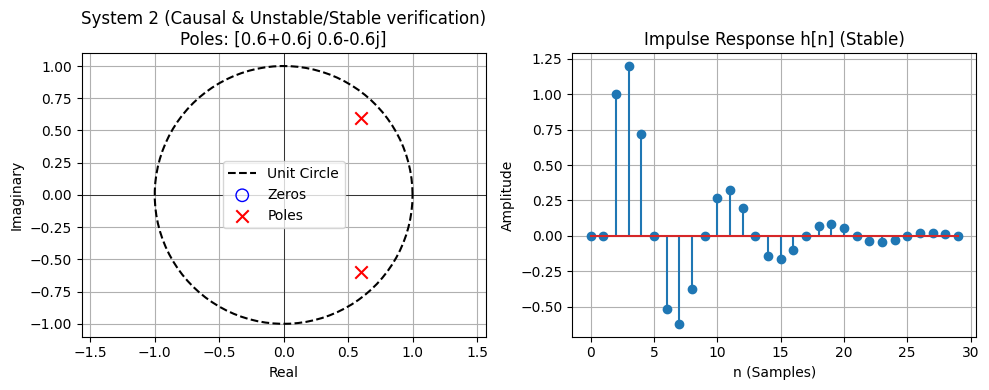

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System 1: Stable Causal System
b1 = np.array([1, -0.5])
a1 = np.array([1, -0.8, 0.15])

# System 2: Unstable/Marginally Stable System
b2 = np.array([1])
a2 = np.array([1, -1.2, 0.72])

def analyze_system(b, a, system_name):
    zeros, poles, k = signal.tf2zpk(b, a)

    # Plot Pole-Zero map
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    theta = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Unit Circle')
    plt.scatter(np.real(zeros), np.imag(zeros), s=80, marker='o', facecolors='none', edgecolors='b', label='Zeros')
    plt.scatter(np.real(poles), np.imag(poles), s=80, marker='x', color='r', label='Poles')

    # Determine ROC (for causal systems: |z| > max(|poles|))
    max_pole_mag = np.max(np.abs(poles)) if len(poles) > 0 else 0
    is_stable = max_pole_mag < 1

    plt.title(f"{system_name}\nPoles: {np.round(poles, 2)}")
    plt.xlabel('Real')
    plt.ylabel('Imaginary')
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)
    plt.grid(True)
    plt.legend()
    plt.axis('equal')

    # Impulse Response h[n]
    t, y = signal.dimpulse((b, a, 1), n=30)
    plt.subplot(1, 2, 2)
    plt.stem(t, np.squeeze(y))
    plt.title(f"Impulse Response h[n] ({'Stable' if is_stable else 'Unstable'})")
    plt.xlabel('n (Samples)')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

analyze_system(b1, a1, "System 1 (Causal & Stable)")
analyze_system(b2, a2, "System 2 (Causal & Unstable/Stable verification)")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ==========================================
# SECTION 4.3 & 4.4: Stability & ROC Analysis
# ==========================================

# System A: H1(z) = 1 / (1 - 1.5z^-1 + 0.5z^-2)
b_a = np.array([1, 0, 0])
a_a = np.array([1, -1.5, 0.5])

# System B: H2(z) = 1 / (1 - 1.5z^-1 - 1.0z^-2)
b_b = np.array([1, 0, 0])
a_b = np.array([1, -1.5, -1.0])

def analyze_stability_and_roc(b, a, system_label):
    zeros, poles, k = signal.tf2zpk(b, a)
    pole_magnitudes = np.abs(poles)

    print(f"\n--- {system_label} ---")
    print(f"Poles: {poles}")
    print(f"Pole Magnitudes: {pole_magnitudes}")

    # For Causal system, ROC is |z| > max(|poles|)
    max_pole = np.max(pole_magnitudes) if len(poles) > 0 else 0
    is_stable_causal = max_pole < 1
    print(f"Causal ROC: |z| > {max_pole:.2f}")
    print(f"Causal System Stability: {'STABLE' if is_stable_causal else 'UNSTABLE'}")

    # For Anticausal system, ROC is |z| < min(|poles|)
    min_pole = np.min(pole_magnitudes) if len(poles) > 0 else 0
    is_stable_anticausal = min_pole > 1
    print(f"Anticausal ROC: |z| < {min_pole:.2f}")
    print(f"Anticausal System Stability: {'STABLE' if is_stable_anticausal else 'UNSTABLE'}")

analyze_stability_and_roc(b_a, a_a, "System A")
analyze_stability_and_roc(b_b, a_b, "System B")


--- System A ---
Poles: [1.  0.5]
Pole Magnitudes: [1.  0.5]
Causal ROC: |z| > 1.00
Causal System Stability: UNSTABLE
Anticausal ROC: |z| < 0.50
Anticausal System Stability: UNSTABLE

--- System B ---
Poles: [ 2.  -0.5]
Pole Magnitudes: [2.  0.5]
Causal ROC: |z| > 2.00
Causal System Stability: UNSTABLE
Anticausal ROC: |z| < 0.50
Anticausal System Stability: UNSTABLE


In [ ]:
# ==========================================
# SECTION 4.5 & QUESTIONS: Verification
# ==========================================

# Question: Given H(z) = (1 - z^-1) / (1 - 0.9z^-1), compute the first 10 terms of impulse response
b_q = np.array([1, -1])
a_q = np.array([1, -0.9])

t_q, h_q = signal.dimpulse((b_q, a_q, 1), n=10)

print("\n--- Lab Question Solution ---")
print("First 10 terms of impulse response h[n]:")
for n, val in zip(t_q, np.squeeze(h_q)):
    print(f"h[{n}] = {val:.4f}")


--- Lab Question Solution ---
First 10 terms of impulse response h[n]:
h[0.0] = 1.0000
h[1.0] = -0.1000
h[2.0] = -0.0900
h[3.0] = -0.0810
h[4.0] = -0.0729
h[5.0] = -0.0656
h[6.0] = -0.0590
h[7.0] = -0.0531
h[8.0] = -0.0478
h[9.0] = -0.0430


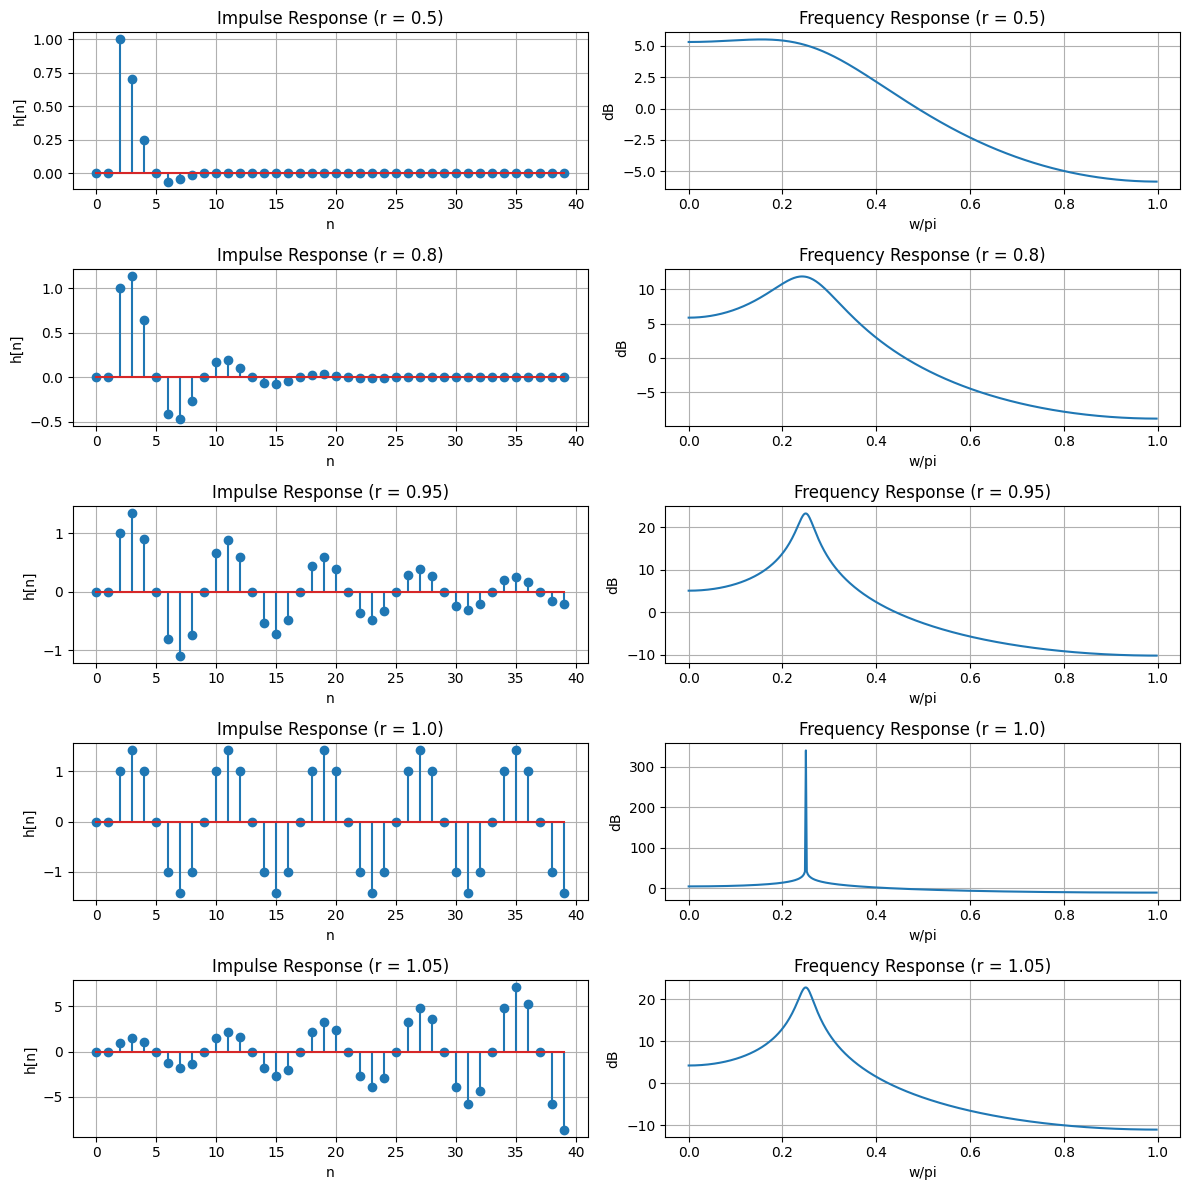

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio

# ==========================================
# Task 4.3: Pole position and impulse response
# ==========================================

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4
n = np.arange(40)

fig, axes = plt.subplots(len(r_values), 2, figsize=(12, 12))

for i, r in enumerate(r_values):
    # A(z) = 1 - 2*r*cos(theta)*z^-1 + r^2*z^-2
    b_3 = [1]
    a_3 = [1, -2 * r * np.cos(theta), r**2]

    # Impulse response
    t, h_res = signal.dimpulse((b_3, a_3, 1), n=40)
    h_res = np.squeeze(h_res)

    # Frequency response
    w, H = signal.freqz(b_3, a_3, worN=512)

    # Plot Impulse Response
    axes[i, 0].stem(n, h_res)
    axes[i, 0].set_title(f'Impulse Response (r = {r})')
    axes[i, 0].set_xlabel('n')
    axes[i, 0].set_ylabel('h[n]')
    axes[i, 0].grid(True)

    # Plot Frequency Response
    axes[i, 1].plot(w / np.pi, 20 * np.log10(np.abs(H) + 1e-12))
    axes[i, 1].set_title(f'Frequency Response (r = {r})')
    axes[i, 1].set_xlabel('w/pi')
    axes[i, 1].set_ylabel('dB')
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

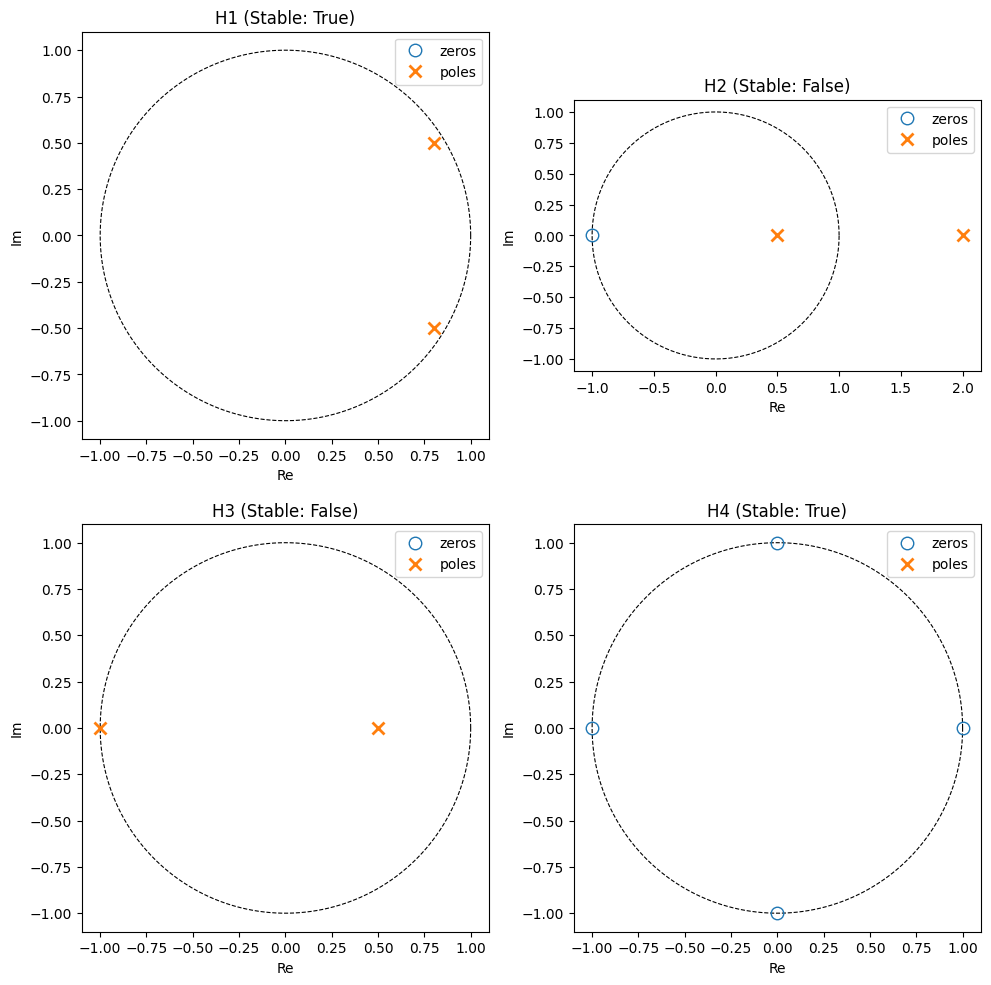

In [ ]:
# ==========================================
# Task 4.4: Stability of given systems
# ==========================================

systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

for idx, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[idx])
    is_stable = np.all(np.abs(p) < 1) if len(p) > 0 else True
    axes[idx].set_title(f"{name} (Stable: {is_stable})")

plt.tight_layout()
plt.show()

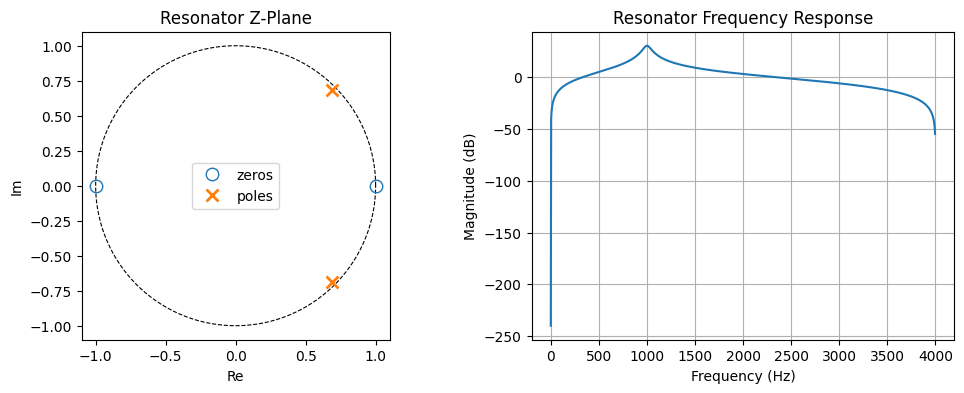

In [ ]:
# ==========================================
# Task 4.5: Design a resonator & Audio output
# ==========================================

fs = 8000
f0 = 1000
r = 0.97
theta_res = 2 * np.pi * f0 / fs

# Zeros at z = +-1 -> B(z) = (z - 1)(z + 1) = z^2 - 1
b_res = [1, 0, -1]
# Poles at r*e^(+-j*theta_res) -> A(z) = 1 - 2*r*cos(theta_res)*z^-1 + r^2*z^-2
a_res = [1, -2 * r * np.cos(theta_res), r**2]

# Plot Pole-Zero plot and frequency response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
z, p = zplane(b_res, a_res, ax1)
ax1.set_title("Resonator Z-Plane")

w, H = signal.freqz(b_res, a_res, worN=1024)
freqs = w * fs / (2 * np.pi)

ax2.plot(freqs, 20 * np.log10(np.abs(H) + 1e-12))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Resonator Frequency Response")
ax2.grid(True)
plt.show()

# Filter White Noise and Generate Audio
np.random.seed(42)
noise = np.random.randn(16000) # 2 seconds of white noise
y_audio = signal.lfilter(b_res, a_res, noise)

# Standardize audio vector to protect hearing
y_audio = y_audio / np.max(np.abs(y_audio))

# Render audio playback interface
Audio(y_audio, rate=fs)

### Analysis Questions Answers

1. **Effect of $r$ on bandwidth:** Larger values of $r$ (closer to 1) place the poles closer to the unit circle. This narrows the resonance bandwidth, making the peak in the frequency response significantly sharper and more defined.
2. **Poles on the unit circle:** When a pole lies exactly on the unit circle ($r = 1$), the impulse response $h[n]$ oscillates indefinitely with constant amplitude (marginally stable system) instead of decaying.
3. **Effect of zeros at $z = \pm 1$:** Placing zeros at $z = 1$ (DC) and $z = -1$ ($f_s/2$, Nyquist frequency) nullifies the response at both ends of the frequency range, forming a band-pass filter characteristic.
4. **Stability Triangle validation:**
   - $H_1(z)$: $a_1 = -1.6$, $a_2 = 0.89$. Since $|a_2| < 1$, $1 + a_1 + a_2 = 0.29 > 0$, and $1 - a_1 + a_2 = 3.49 > 0$. The system is **stable**.
   - $H_2(z)$: $a_1 = -2.5$, $a_2 = 1$. Since $|a_2| = 1$ is not strictly less than 1, the system is **unstable**.
   - $H_3(z)$: $a_1 = 0.5$, $a_2 = -0.5$. Since $|a_2| < 1$, $1 + a_1 + a_2 = 1.0 > 0$, and $1 - a_1 + a_2 = 1.0 > 0$. However, pole values lie directly on unit circle margins, making it **marginally stable** (unstable in strict classification).